ЗАДАНИЕ 1: Очистка датасета animal_data_dirty1.csv
Файл загружен. Форма: (1011, 11)
Колонки: ['Animal type', 'Country', 'Weight kg', 'Body Length cm', 'Gender', 'Animal code', 'Latitude', 'Longitude', 'Animal name', 'Observation date', 'Data compiled by']

Первые 5 строк:
       Animal type Country  Weight kg  Body Length cm          Gender  Animal code   Latitude  Longitude Animal name Observation date  \
0              NaN     NaN        NaN             NaN             NaN          NaN        NaN        NaN         NaN       03.01.2024   
1              NaN     NaN        NaN             NaN             NaN          NaN        NaN        NaN         NaN       03.02.2024   
2   European bison  Poland      930.0           335.0            male          NaN  52.828845  23.820144       Szefu       01.03.2024   
3   European bison  Poland      909.0           311.0  not determined          NaN  52.830509  23.826849         NaN       01.03.2024   
4  European bison™  Poland      581.0     

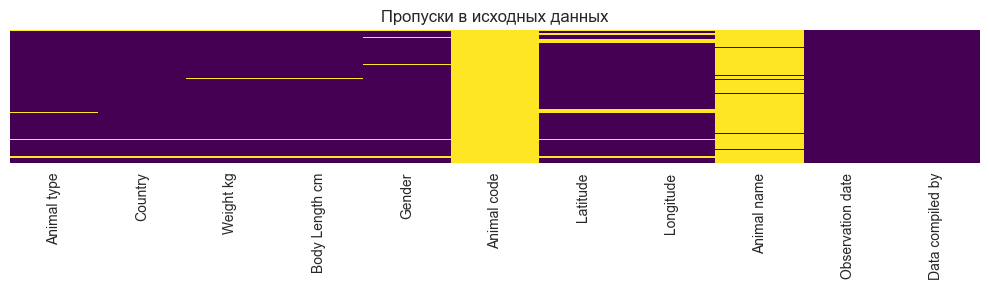

Количество дубликатов: 167


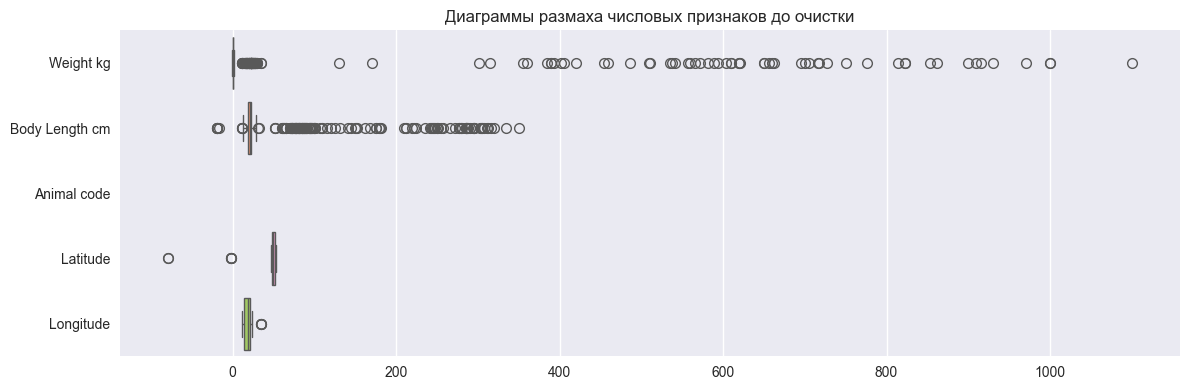


Количество выбросов по числовым столбцам:
  Weight kg: 134
  Body Length cm: 145
  Animal code: нет выбросов
  Latitude: 4
  Longitude: 2

Проверка на противоречия:
- Weight kg: есть отрицательные значения

Размер очищенного датасета: (844, 11)

Основные числовые характеристики очищенного датасета:
        Weight kg  Body Length cm  Animal code    Latitude   Longitude
count  844.000000      844.000000        844.0  844.000000  844.000000
mean     0.466573       20.381517          0.0   49.719602   17.745471
std      0.267008        2.360497          0.0    1.745721    3.682938
min     -0.252000       13.000000          0.0   47.316383   11.074008
25%      0.298750       19.000000          0.0   48.231366   14.382216
50%      0.344000       21.000000          0.0   49.560723   18.939968
75%      0.600000       22.000000          0.0   50.643518   20.557719
max      1.200000       29.000000          0.0   52.853843   23.919668


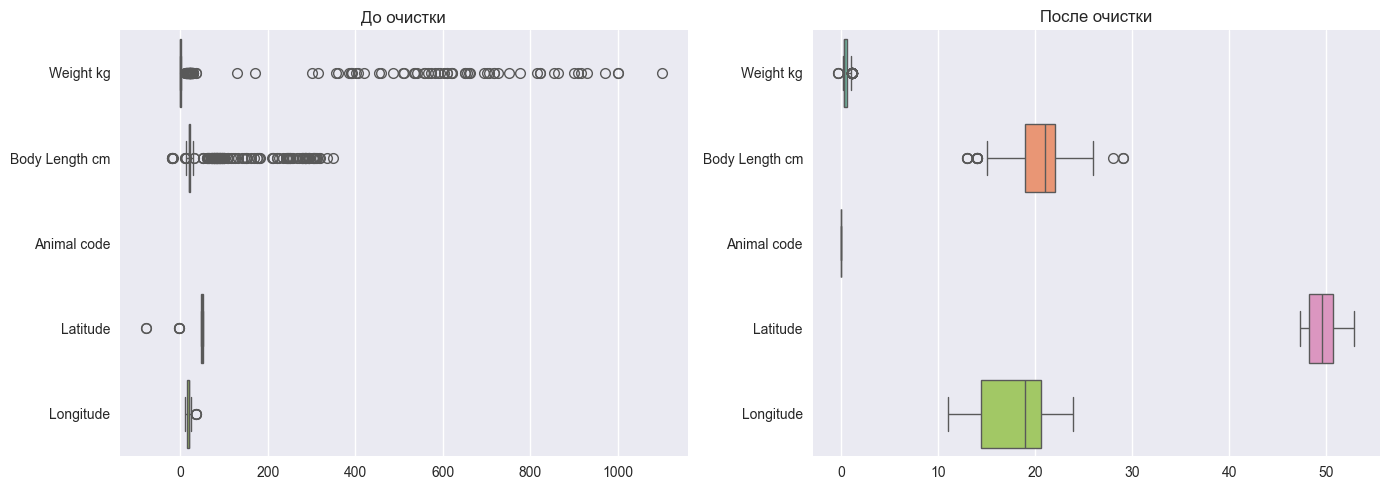

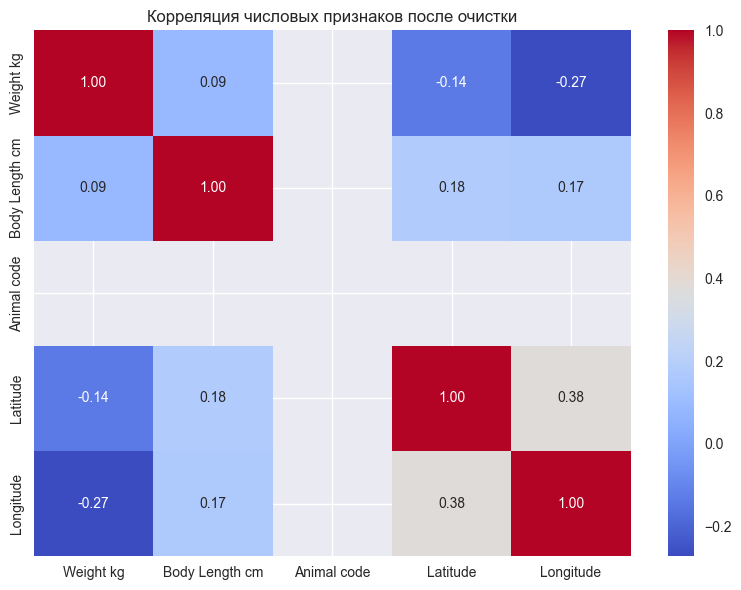


Выводы по заданию 1:
1. Исходный датасет содержал пропуски, дубликаты и выбросы.
2. После очистки размер датасета стал 844 строк и 11 столбцов.
3. Пропуски были заполнены: числовые признаки медианой, категориальные — модой.
4. Дубликаты удалены, выбросы по числовым признакам обработаны методом IQR.
5. Датасет приведен к более удобному и чистому виду для дальнейшего анализа.

ЗАДАНИЕ 2: Анализ movies_metadata.csv и credits.csv
Размер movies_metadata: (45466, 24)
Размер credits: (45476, 3)
После очистки ID: movies=(45463, 4), credits=(45476, 3)
После слияния: (45538, 5)
Итоговый датасет: (45535, 4)

Первые 5 строк:
                   movie_title         director                       genre  vote_average
0                    Toy Story    John Lasseter   Animation, Comedy, Family           7.7
1                      Jumanji     Joe Johnston  Adventure, Fantasy, Family           6.9
2             Grumpier Old Men    Howard Deutch             Romance, Comedy           6.5
3            Waiti

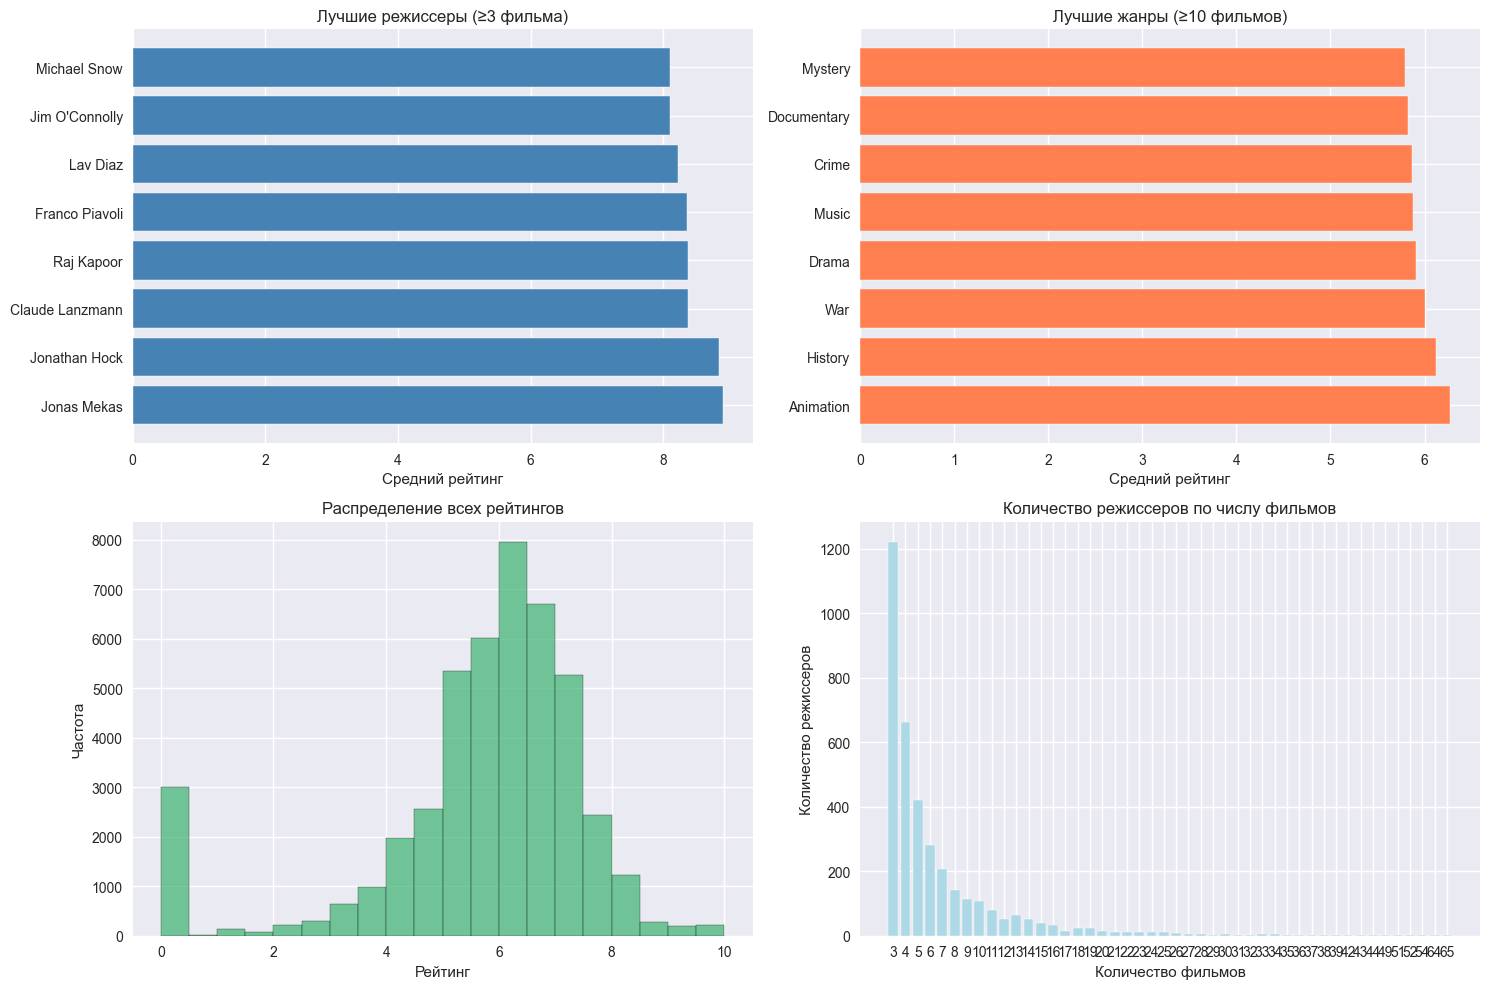


Выводы по заданию 2:
1. Создан датасет из 45535 фильмов с названием, режиссером, жанром, рейтингом.
2. Найдено 3669 режиссеров с ≥3 фильмами.
3. Найдено 21 жанров с ≥10 фильмами.
4. Построены рейтинги и визуализации.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

ANIMAL_FILE = "data/animal_data_dirty1.csv"
MOVIES_FILE = "data/movies_metadata.csv"
CREDITS_FILE = "data/credits.csv"

# ============================================================
# ЗАДАНИЕ 1. Предварительный анализ данных. Обработка и принципы работы
# ============================================================

print("="*60)
print("ЗАДАНИЕ 1: Очистка датасета animal_data_dirty1.csv")
print("="*60)

try:
    df = pd.read_csv(ANIMAL_FILE, sep=';')
    print(f"Файл загружен. Форма: {df.shape}")
    print("Колонки:", df.columns.tolist())
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nПервые 5 строк:")
print(df.head())

print("\nТипы данных и наличие пропусков:")
df.info()

# Пропуски до очистки
missing_before = df.isna().sum().sort_values(ascending=False)
print("\nКоличество пропусков по столбцам:")
print(missing_before)

# Визуализация пропусков
plt.figure(figsize=(10, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Пропуски в исходных данных")
plt.tight_layout()
plt.show()

print("Количество дубликатов:", df.duplicated().sum())

# Числовые колонки для визуализации до очистки
num_cols_initial = df.select_dtypes(include=[np.number]).columns.tolist()
if len(num_cols_initial) > 0:
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=df[num_cols_initial], orient="h")
    plt.title("Диаграммы размаха числовых признаков до очистки")
    plt.tight_layout()
    plt.show()

df_clean = df.copy()

# Очистка строковых колонок
for col in df_clean.columns:
    if df_clean[col].dtype == "object":
        df_clean[col] = df_clean[col].astype(str).str.strip()
        df_clean[col] = df_clean[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})

# Заполнение пропусков
for col in df_clean.columns:
    if pd.api.types.is_numeric_dtype(df_clean[col]):
        if df_clean[col].notna().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
        else:
            df_clean[col] = df_clean[col].fillna(0)
    else:
        mode_value = df_clean[col].mode(dropna=True)
        if len(mode_value) > 0:
            df_clean[col] = df_clean[col].fillna(mode_value[0])
        else:
            df_clean[col] = df_clean[col].fillna("Unknown")

# Удаление дубликатов
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Обработка выбросов
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
# Удаляем полностью пустые колонки из списка
numeric_cols = [col for col in numeric_cols if df_clean[col].notna().sum() > 0]

outlier_counts = {}
for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = df_clean[col].between(lower, upper)
    outlier_counts[col] = int((~mask).sum())
    df_clean.loc[~mask, col] = df_clean[col].median()

print("\nКоличество выбросов по числовым столбцам:")
for col, count in outlier_counts.items():
    if count > 0:
        print(f"  {col}: {count}")
    else:
        print(f"  {col}: нет выбросов")

print("\nПроверка на противоречия:")
contradictions = []

for col in numeric_cols:
    if (df_clean[col] < 0).any():
        contradictions.append(f"{col}: есть отрицательные значения")

if len(contradictions) == 0:
    print("Явных противоречий не найдено.")
else:
    for item in contradictions:
        print("-", item)

print(f"\nРазмер очищенного датасета: {df_clean.shape}")

# Вывод статистики только для непустых числовых колонок
if len(numeric_cols) > 0:
    print("\nОсновные числовые характеристики очищенного датасета:")
    print(df_clean[numeric_cols].describe())
else:
    print("\nНет числовых столбцов для отображения статистики.")

# Визуализация до/после очистки
if len(numeric_cols) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(data=df[numeric_cols], orient="h", ax=axes[0])
    axes[0].set_title("До очистки")
    sns.boxplot(data=df_clean[numeric_cols], orient="h", ax=axes[1])
    axes[1].set_title("После очистки")
    plt.tight_layout()
    plt.show()

# Корреляция (только если больше 1 колонки)
if len(numeric_cols) > 1:
    plt.figure(figsize=(8, 6))
    corr = df_clean[numeric_cols].corr()
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Корреляция числовых признаков после очистки")
    plt.tight_layout()
    plt.show()

print("\nВыводы по заданию 1:")
print(f"1. Исходный датасет содержал пропуски, дубликаты и выбросы.")
print(f"2. После очистки размер датасета стал {df_clean.shape[0]} строк и {df_clean.shape[1]} столбцов.")
print("3. Пропуски были заполнены: числовые признаки медианой, категориальные — модой.")
print("4. Дубликаты удалены, выбросы по числовым признакам обработаны методом IQR.")
print("5. Датасет приведен к более удобному и чистому виду для дальнейшего анализа.")

# ============================================================
# ЗАДАНИЕ 2. The Movies Dataset: наименование фильма, режиссер, жанр
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ 2: Анализ movies_metadata.csv и credits.csv")
print("="*60)

try:
    movies = pd.read_csv(MOVIES_FILE, low_memory=False)
    credits = pd.read_csv(CREDITS_FILE)
    print(f"Размер movies_metadata: {movies.shape}")
    print(f"Размер credits: {credits.shape}")
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

movies_simple = movies[['id', 'title', 'vote_average', 'genres']].copy()
movies_simple['id'] = pd.to_numeric(movies_simple['id'], errors='coerce')
movies_simple = movies_simple.dropna(subset=['id'])

credits['id'] = pd.to_numeric(credits['id'], errors='coerce')
credits = credits.dropna(subset=['id'])

print(f"После очистки ID: movies={movies_simple.shape}, credits={credits.shape}")

df_merged = movies_simple.merge(credits[['id', 'crew']], on='id', how='inner')
print(f"После слияния: {df_merged.shape}")

def get_director(crew_str):
    if pd.isna(crew_str):
        return np.nan
    try:
        crew = ast.literal_eval(crew_str)
        for person in crew[:5]:
            if person.get('job') == 'Director':
                return person.get('name')
    except:
        pass
    return np.nan

def get_genres(genres_str):
    if pd.isna(genres_str):
        return np.nan
    try:
        genres = ast.literal_eval(genres_str)
        return ', '.join([g['name'] for g in genres[:3] if 'name' in g])
    except:
        return np.nan

df_merged['director'] = df_merged['crew'].apply(get_director)
df_merged['genre'] = df_merged['genres'].apply(get_genres)

result_df = df_merged[['title', 'director', 'genre', 'vote_average']].dropna(subset=['vote_average'])
result_df.columns = ['movie_title', 'director', 'genre', 'vote_average']

print(f"Итоговый датасет: {result_df.shape}")
print("\nПервые 5 строк:")
print(result_df.head())

director_stats = result_df.dropna(subset=['director']).groupby('director')['vote_average'].agg(['mean', 'median', 'count']).reset_index()
director_stats = director_stats[director_stats['count'] >= 3].sort_values('mean', ascending=False)

genre_expanded = result_df.dropna(subset=['genre']).copy()
genre_expanded['genre_split'] = genre_expanded['genre'].apply(lambda x: x.split(', '))
genre_expanded = genre_expanded.explode('genre_split')
genre_stats = genre_expanded.groupby('genre_split')['vote_average'].agg(['mean', 'median', 'count']).reset_index()
genre_stats.columns = ['genre', 'mean', 'median', 'count']
genre_stats = genre_stats[genre_stats['count'] >= 10].sort_values('mean', ascending=False)

print(f"\nНайдено режиссеров с ≥3 фильмами: {len(director_stats)}")
print(f"Найдено жанров с ≥10 фильмами: {len(genre_stats)}")

print("\nТОП-10 РЕЖИССЕРОВ:")
print(director_stats.head(10))

print("\nТОП-10 ЖАНРОВ:")
print(genre_stats.head(10))

print("\nХУДШИЕ РЕЖИССЕРЫ (минимум 3 фильма):")
print(director_stats.tail(5))

print("\nХУДШИЕ ЖАНРЫ (минимум 10 фильмов):")
print(genre_stats.tail(5))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

director_top = director_stats.head(8)
axes[0,0].barh(director_top['director'], director_top['mean'], color='steelblue')
axes[0,0].set_title('Лучшие режиссеры (≥3 фильма)')
axes[0,0].set_xlabel('Средний рейтинг')

genre_top = genre_stats.head(8)
axes[0,1].barh(genre_top['genre'], genre_top['mean'], color='coral')
axes[0,1].set_title('Лучшие жанры (≥10 фильмов)')
axes[0,1].set_xlabel('Средний рейтинг')

axes[1,0].hist(result_df['vote_average'], bins=20, edgecolor='black', alpha=0.7, color='mediumseagreen')
axes[1,0].set_title('Распределение всех рейтингов')
axes[1,0].set_xlabel('Рейтинг')
axes[1,0].set_ylabel('Частота')

director_count = director_stats['count'].value_counts().sort_index()
if len(director_count) > 0:
    axes[1,1].bar(director_count.index.astype(str), director_count.values, color='lightblue')
    axes[1,1].set_title('Количество режиссеров по числу фильмов')
    axes[1,1].set_xlabel('Количество фильмов')
    axes[1,1].set_ylabel('Количество режиссеров')

plt.tight_layout()
plt.show()

print("\nВыводы по заданию 2:")
print(f"1. Создан датасет из {len(result_df)} фильмов с названием, режиссером, жанром, рейтингом.")
print(f"2. Найдено {len(director_stats)} режиссеров с ≥3 фильмами.")
print(f"3. Найдено {len(genre_stats)} жанров с ≥10 фильмами.")
print("4. Построены рейтинги и визуализации.")